# DeepWeeds — paper-fold validation error analysis and validation/test metrics
**Inference only · Scratch ViT vs fine-tuned Hugging Face ViT-B/16 · local VS Code**



## 0 · Local setup
Open this notebook in VS Code with the project Python environment. Install dependencies once in the VS Code terminal:
```bash
python -m pip install torch torchvision transformers scikit-learn pandas numpy matplotlib pillow ipykernel
```


In [1]:
from pathlib import Path
import sys, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, log_loss)
from IPython.display import display

SEED = 42
VAL_FOLD = 0
SPLIT = "paper"
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0  # robust for VS Code/Windows notebooks
N_GALLERY = 12
BOOTSTRAP_REPS = 1000
PROJECT_ROOT_OVERRIDE = None  # e.g. Path(r"C:\Users\me\CS3244-DeepWeeds")
SCRATCH_CKPT_OVERRIDE = None
HF_CKPT_OVERRIDE = None

def locate_root():
    if PROJECT_ROOT_OVERRIDE is not None:
        root = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not (root / "splits/folds_paper.csv").is_file():
            raise FileNotFoundError(f"Missing splits/folds_paper.csv under {root}")
        return root
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "splits/folds_paper.csv").is_file() and (p / "src/data_pipeline.py").is_file():
            return p
    raise FileNotFoundError("Could not find project root; set PROJECT_ROOT_OVERRIDE above.")

ROOT = locate_root()
sys.path.insert(0, str(ROOT))
OUT = ROOT / "outputs/vit/paper_fold_validation_analysis"
OUT.mkdir(parents=True, exist_ok=True)
IMG_DIR = ROOT / "data/images"
SCRATCH_PATH = Path(SCRATCH_CKPT_OVERRIDE) if SCRATCH_CKPT_OVERRIDE else ROOT / "checkpoints/vit_scratch_best.pt"
HF_PATH = Path(HF_CKPT_OVERRIDE) if HF_CKPT_OVERRIDE else ROOT / "checkpoints/vit_hf_vit_base_patch16_224_in21k_finetuned_best.pt"
for path in (IMG_DIR, ROOT / "splits/folds_paper.csv", SCRATCH_PATH, HF_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Required local file/folder missing: {path}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("Root:", ROOT, "\nDevice:", device, "\nOutput:", OUT)

Root: C:\Coding\CS3244\Github\CS3244-DeepWeeds 
Device: cpu 
Output: C:\Coding\CS3244\Github\CS3244-DeepWeeds\outputs\vit\paper_fold_validation_analysis


## 1 · Verify paper fold and build validation/test loaders


In [2]:
from src.data_pipeline import DeepWeedsDataset, make_transforms
from src.metrics import SPECIES
from torch.utils.data import DataLoader

folds = pd.read_csv(
    ROOT / "splits" / "folds_paper.csv",
    dtype={"session": str}
).copy()
fold_col = f"paper_fold{VAL_FOLD}"
assert {"Filename", "Label", "Species", fold_col}.issubset(folds.columns)
assert not folds["Filename"].duplicated().any(), "Duplicate filenames in fold manifest"
assert folds[fold_col].isin(["train", "val", "test"]).all(), "Unexpected paper split assignment"
train_manifest = folds.loc[folds[fold_col] == "train"].copy()
val_manifest = folds.loc[folds[fold_col] == "val"].copy()
test_manifest = folds.loc[folds[fold_col] == "test"].copy()
assert all(len(part) > 0 for part in (train_manifest, val_manifest, test_manifest))
for left, right in ((train_manifest, val_manifest), (train_manifest, test_manifest), (val_manifest, test_manifest)):
    assert set(left.Filename).isdisjoint(right.Filename), "Overlapping split filenames"
classes = list(SPECIES)
assert len(classes) == 9
for part in (val_manifest, test_manifest):
    assert (part["Label"].map(lambda i: classes[int(i)]) == part["Species"]).all(), "Class labels disagree with SPECIES"
val_loader = DataLoader(DeepWeedsDataset(val_manifest, IMG_DIR, make_transforms(False), classes),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(DeepWeedsDataset(test_manifest, IMG_DIR, make_transforms(False), classes),
                         batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"Paper fold {VAL_FOLD}: train={len(train_manifest):,}, validation={len(val_manifest):,}, test={len(test_manifest):,}")
display(pd.DataFrame({
    "validation": val_manifest["Species"].value_counts().reindex(classes, fill_value=0),
    "test": test_manifest["Species"].value_counts().reindex(classes, fill_value=0),
}))


Paper fold 0: train=10,501, validation=3,501, test=3,507


,validation,test
Species,,
Chinee apple,225,226
Lantana,213,213
Parkinsonia,206,207
Parthenium,204,205
Prickly acacia,212,213
Rubber vine,202,202
Siam weed,215,215
Snake weed,203,204
Negative,1821,1822


## 2 · Reconstruct the exact architectures and load checkpoints


In [3]:
class ScratchViT(nn.Module):
    def __init__(self, num_classes, image_size=224, patch_size=16, embed_dim=384,
                 depth=6, num_heads=6, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        assert image_size % patch_size == 0
        n_patches = (image_size // patch_size) ** 2
        self.patch_size = patch_size
        self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))
        self.head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Dropout(dropout),
                                  nn.Linear(embed_dim, num_classes))
    def forward(self, x):
        x = self.patch_embed(x).flatten(2).transpose(1, 2)
        x = torch.cat((self.cls_token.expand(x.shape[0], -1, -1), x), dim=1) + self.pos_embed
        return self.head(self.encoder(self.pos_drop(x))[:, 0])

from transformers import ViTConfig, ViTForImageClassification

class HFViTClassifier(nn.Module):
    def __init__(self, hf_model):
        super().__init__()
        self.hf_model = hf_model
    def forward(self, pixel_values):
        return self.hf_model(pixel_values=pixel_values).logits

def read_checkpoint(path):
    # Only load trusted checkpoint files; PyTorch checkpoint format uses pickle internally.
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    assert isinstance(ckpt, dict) and "model_state_dict" in ckpt
    assert list(ckpt["classes"]) == classes, f"Class ordering differs in {path.name}"
    assert ckpt.get("split") == SPLIT and int(ckpt.get("val_fold")) == VAL_FOLD
    return ckpt

scratch_ckpt = read_checkpoint(SCRATCH_PATH)
hf_ckpt = read_checkpoint(HF_PATH)

scratch_model = ScratchViT(len(classes), image_size=IMAGE_SIZE, patch_size=16,
                           embed_dim=384, depth=6, num_heads=6, dropout=0.1)
scratch_model.load_state_dict(scratch_ckpt["model_state_dict"], strict=True)

config = ViTConfig(
    image_size=224, patch_size=16, num_channels=3, hidden_size=768,
    num_hidden_layers=12, num_attention_heads=12, intermediate_size=3072,
    hidden_act="gelu", hidden_dropout_prob=0.0, attention_probs_dropout_prob=0.0,
    layer_norm_eps=1e-12, qkv_bias=True, num_labels=len(classes),
    id2label={i: name for i, name in enumerate(classes)},
    label2id={name: i for i, name in enumerate(classes)},
)
hf_model = HFViTClassifier(ViTForImageClassification(config))
def adapt_hf_vit_state_dict(saved_state, target_state):
    """Translate ViT key names across Transformers implementations; never drop weights."""
    if set(saved_state) == set(target_state):
        return saved_state
    converted = {}
    import re
    replacements = {
        "attention.q_proj.": "attention.attention.query.",
        "attention.k_proj.": "attention.attention.key.",
        "attention.v_proj.": "attention.attention.value.",
        "attention.o_proj.": "attention.output.dense.",
        "mlp.fc1.": "intermediate.dense.",
        "mlp.fc2.": "output.dense.",
    }
    for key, tensor in saved_state.items():
        new_key = re.sub(r"^(hf_model\.vit\.)layers\.(\d+)\.",
                         r"\1encoder.layer.\2.", key)
        for old, new in replacements.items():
            new_key = new_key.replace(old, new)
        if new_key in converted:
            raise ValueError(f"Checkpoint key collision: {new_key}")
        converted[new_key] = tensor
    missing = sorted(set(target_state) - set(converted))
    unexpected = sorted(set(converted) - set(target_state))
    mismatched = [(key, tuple(converted[key].shape), tuple(target_state[key].shape))
                  for key in set(converted) & set(target_state)
                  if converted[key].shape != target_state[key].shape]
    if missing or unexpected or mismatched:
        raise RuntimeError(f"Checkpoint translation incomplete: missing={missing[:5]}, "
                           f"unexpected={unexpected[:5]}, shapes={mismatched[:5]}")
    print(f"Verified all {len(converted)} fine-tuned ViT tensors against local architecture")
    return converted

hf_weights = adapt_hf_vit_state_dict(hf_ckpt["model_state_dict"], hf_model.state_dict())
hf_model.load_state_dict(hf_weights, strict=True)

models = {"Scratch ViT": scratch_model, "Fine-tuned ViT-B/16": hf_model}
for name, model in models.items():
    model.to(device).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    print(f"{name}: checkpoint restored, frozen, eval mode")

c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\nn\modules\transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Verified all 200 fine-tuned ViT tensors against local architecture
Scratch ViT: checkpoint restored, frozen, eval mode
Fine-tuned ViT-B/16: checkpoint restored, frozen, eval mode


In [4]:
from pathlib import Path
import pandas as pd

# Use the same project structure as your training script
PROJECT_ROOT = IMG_DIR.parent.parent
FOLDS_PATH = PROJECT_ROOT / "splits" / "folds_paper.csv"

print("Project root:", PROJECT_ROOT)
print("Images directory:", IMG_DIR)
print("Splits file:", FOLDS_PATH)
print("Splits file exists:", FOLDS_PATH.is_file())

Project root: C:\Coding\CS3244\Github\CS3244-DeepWeeds
Images directory: C:\Coding\CS3244\Github\CS3244-DeepWeeds\data\images
Splits file: C:\Coding\CS3244\Github\CS3244-DeepWeeds\splits\folds_paper.csv
Splits file exists: True


In [5]:
folds = pd.read_csv(FOLDS_PATH)

print("=== SPECIES DISTRIBUTION ===")
print(pd.crosstab(
    folds["Species"],
    folds[fold_col],
    margins=True
))

print("\n=== PARKINSONIA ===")
p = folds[
    folds["Species"].astype(str).str.contains(
        "parkinsonia", case=False, na=False
    )
]

print("Total Parkinsonia:", len(p))
print("Parkinsonia in validation:", (p[fold_col] == "val").sum())
print("Parkinsonia in test:", (p[fold_col] == "test").sum())
print("Parkinsonia in train:", (p[fold_col] == "train").sum())

print("\n=== CHECK IMAGE FILES ===")
folds["file_exists"] = folds["Filename"].apply(
    lambda f: (IMG_DIR / str(f)).is_file()
)

print("Total images:", len(folds))
print("Existing files:", folds["file_exists"].sum())
print("Missing files:", (~folds["file_exists"]).sum())

print("\n=== MISSING FILES BY SPECIES ===")
print(pd.crosstab(folds["Species"], folds["file_exists"]))

=== SPECIES DISTRIBUTION ===
paper_fold0     test  train   val    All
Species                                 
Chinee apple     226    674   225   1125
Lantana          213    638   213   1064
Negative        1822   5463  1821   9106
Parkinsonia      207    618   206   1031
Parthenium       205    613   204   1022
Prickly acacia   213    637   212   1062
Rubber vine      202    605   202   1009
Siam weed        215    644   215   1074
Snake weed       204    609   203   1016
All             3507  10501  3501  17509

=== PARKINSONIA ===
Total Parkinsonia: 1031
Parkinsonia in validation: 206
Parkinsonia in test: 207
Parkinsonia in train: 618

=== CHECK IMAGE FILES ===
Total images: 17509
Existing files: 17509
Missing files: 0

=== MISSING FILES BY SPECIES ===
file_exists     True
Species             
Chinee apple    1125
Lantana         1064
Negative        9106
Parkinsonia     1031
Parthenium      1022
Prickly acacia  1062
Rubber vine     1009
Siam weed       1074
Snake weed      1016


In [6]:
print("=== PARKINSONIA SESSION DISTRIBUTION ===")

p = folds[folds["Species"] == "Parkinsonia"]

print("Unique Parkinsonia sessions:", p["session"].nunique())

display(
    p.groupby(["session", fold_col])
     .size()
     .reset_index(name="image_count")
     .sort_values("image_count", ascending=False)
     .head(30)
)

print("\n=== ALL SPECIES: UNIQUE SESSIONS ===")

display(
    folds.groupby("Species")["session"]
    .nunique()
    .sort_values()
)

=== PARKINSONIA SESSION DISTRIBUTION ===
Unique Parkinsonia sessions: 6


,session,paper_fold0,image_count
7,20170920-3,train,146
4,20170920-2,train,127
1,20170920-1,train,126
10,20171102-1,train,86
16,20171102-3,train,67
13,20171102-2,train,66
5,20170920-2,val,55
6,20170920-3,test,54
8,20170920-3,val,50
0,20170920-1,test,45



=== ALL SPECIES: UNIQUE SESSIONS ===


Species
Parkinsonia        6
Siam weed          8
Parthenium         9
Rubber vine       11
Lantana           16
Prickly acacia    16
Snake weed        21
Chinee apple      23
Negative          53
Name: session, dtype: int64

## 3 · Inference on validation and test


In [7]:
# The original training script reads batch[0] and batch[1] only.
from torch.utils.data import DataLoader, Dataset

class TestDatasetWithFilename(Dataset):
    def __init__(self, original):
        self.original = original
        if not hasattr(original, "df") or "Filename" not in original.df.columns:
            raise ValueError("Test dataset has no .df['Filename']; cannot safely match predictions to images.")
        self.filenames = original.df["Filename"].astype(str).tolist()
        if len(self.filenames) != len(original):
            raise ValueError("Dataset filename count differs from dataset length")

    def __len__(self):
        return len(self.original)

    def __getitem__(self, idx):
        sample = self.original[idx]
        if not isinstance(sample, (tuple, list)) or len(sample) < 2:
            raise TypeError("Expected original dataset sample (image, label[, ...])")
        # Ignore any third field in the original sample; use verified DataFrame order.
        return sample[0], sample[1], self.filenames[idx]

val_loader = DataLoader(TestDatasetWithFilename(val_loader.dataset),
                        batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, drop_last=False)
test_loader = DataLoader(TestDatasetWithFilename(test_loader.dataset),
                         batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, drop_last=False)

def predict_split(model, loader, manifest):
    rows = []
    model.eval()
    with torch.inference_mode():
        for batch in loader:
            assert len(batch) == 3, "Expected wrapped test batch (image, label, filename)"
            images, labels, filenames = batch[0], batch[1], batch[2]
            images = images.to(device)
            logits = model(images)
            if hasattr(logits, "logits"):
                logits = logits.logits
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            for y, filename, prob in zip(labels.cpu().numpy(), filenames, probs):
                row = {"Filename": str(filename), "y_true": int(y),
                       "y_pred": int(prob.argmax()), "confidence": float(prob.max()),
                       "true_class_probability": float(prob[int(y)])}
                row.update({f"p_{j}": float(prob[j]) for j in range(len(classes))})
                rows.append(row)
    result = pd.DataFrame(rows)
    assert result["Filename"].is_unique
    assert set(result["Filename"]) == set(manifest["Filename"].astype(str))
    label_map = manifest.set_index("Filename")["Species"].astype(str)
    assert (result["y_true"].map(lambda i: classes[i]) == result["Filename"].map(label_map)).all(), "Labels disagree with split manifest"
    result["true_class"] = result["y_true"].map(dict(enumerate(classes)))
    result["predicted_class"] = result["y_pred"].map(dict(enumerate(classes)))
    result["correct"] = result["y_true"] == result["y_pred"]
    return result.sort_values("Filename").reset_index(drop=True)

predictions = {}  # All downstream detailed error analysis uses VALIDATION ONLY.
test_predictions = {}  # Aggregate test metrics only; no test error analysis.
for name, model in models.items():
    print("Evaluating validation:", name)
    predictions[name] = predict_split(model, val_loader, val_manifest)
    slug = "scratch" if name.startswith("Scratch") else "finetuned"
    predictions[name].to_csv(OUT / f"{slug}_validation_predictions.csv", index=False)
    print("Evaluating test aggregate metrics:", name)
    test_predictions[name] = predict_split(model, test_loader, test_manifest)
print("Inference complete. No model training performed.")


Evaluating validation: Scratch ViT
Evaluating test aggregate metrics: Scratch ViT
Evaluating validation: Fine-tuned ViT-B/16
Evaluating test aggregate metrics: Fine-tuned ViT-B/16
Inference complete. No model training performed.


## 4 · Separate validation and test performance tables


=== VALIDATION METRICS (paper fold validation) ===


c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,n_images,correct,incorrect,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,cross_entropy,weed_to_negative_count,weed_to_negative_rate,negative_to_weed_count,negative_to_weed_rate
Scratch ViT,3501.0,2187.0,1314.0,0.6247,0.5977,0.6360,0.5535,0.6988,1.0207,79.0,0.0470,840.0,0.4613
Fine-tuned ViT-B/16,3501.0,3287.0,214.0,0.9389,0.9267,0.9397,0.9032,0.9530,0.2424,16.0,0.0095,141.0,0.0774


=== TEST METRICS (paper fold test; aggregate only) ===


,n_images,correct,incorrect,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall,cross_entropy,weed_to_negative_count,weed_to_negative_rate,negative_to_weed_count,negative_to_weed_rate
Scratch ViT,3507.0,2147.0,1360.0,0.6122,0.5729,0.6254,0.5349,0.6689,1.0198,82.0,0.0487,825.0,0.4528
Fine-tuned ViT-B/16,3507.0,3270.0,237.0,0.9324,0.9213,0.9332,0.8936,0.9527,0.2569,18.0,0.0107,166.0,0.0911


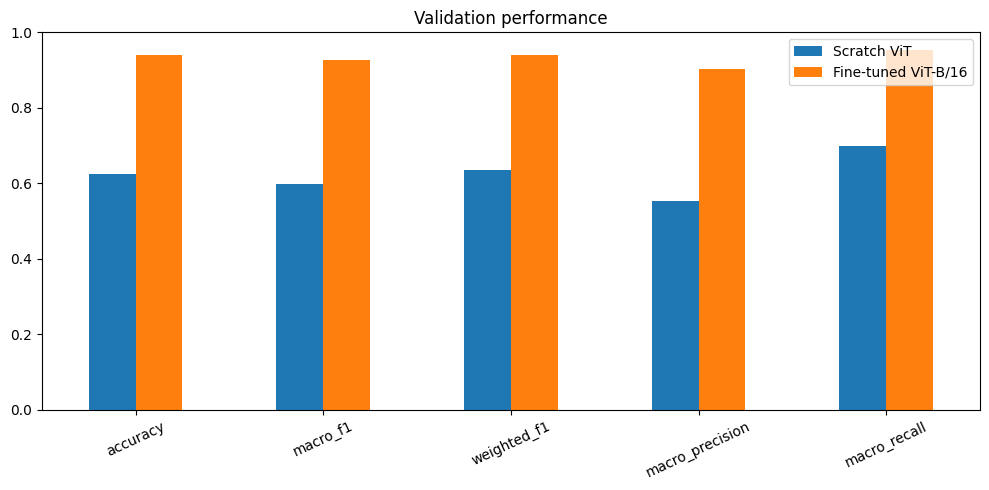

In [8]:
negative_idx = next((i for i, c in enumerate(classes) if c.strip().lower() == "negative"), None)
assert negative_idx is not None, "Cannot find Negative class"

def overall_metrics(frame):
    y, pred = frame.y_true.to_numpy(), frame.y_pred.to_numpy()
    weed = y != negative_idx
    negative = y == negative_idx
    return {
        "n_images": len(frame), "correct": int((y == pred).sum()), "incorrect": int((y != pred).sum()),
        "accuracy": accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, labels=range(len(classes)), average="macro", zero_division=0),
        "weighted_f1": f1_score(y, pred, labels=range(len(classes)), average="weighted", zero_division=0),
        "macro_precision": precision_score(y, pred, labels=range(len(classes)), average="macro", zero_division=0),
        "macro_recall": recall_score(y, pred, labels=range(len(classes)), average="macro", zero_division=0),
        "cross_entropy": log_loss(y, frame[[f"p_{i}" for i in range(len(classes))]].to_numpy(), labels=list(range(len(classes)))),
        "weed_to_negative_count": int((weed & (pred == negative_idx)).sum()),
        "weed_to_negative_rate": float((pred[weed] == negative_idx).mean()),
        "negative_to_weed_count": int((negative & (pred != negative_idx)).sum()),
        "negative_to_weed_rate": float((pred[negative] != negative_idx).mean()) if negative.any() else np.nan,
    }

validation_overall = pd.DataFrame({name: overall_metrics(frame) for name, frame in predictions.items()}).T
test_overall = pd.DataFrame({name: overall_metrics(frame) for name, frame in test_predictions.items()}).T
print("=== VALIDATION METRICS (paper fold validation) ===")
display(validation_overall.round(4))
print("=== TEST METRICS (paper fold test; aggregate only) ===")
display(test_overall.round(4))
validation_overall.to_csv(OUT / "validation_overall_comparison.csv")
test_overall.to_csv(OUT / "test_overall_comparison.csv")
validation_overall[["accuracy", "macro_f1", "weighted_f1", "macro_precision", "macro_recall"]].T.plot.bar(figsize=(10, 5), rot=25)
plt.ylim(0, 1); plt.title("Validation performance"); plt.tight_layout()
plt.savefig(OUT / "overall_metrics.png", dpi=180); plt.show()


## 5 · Per-class performance and model comparison

,class,precision,recall,f1,support,correct,errors,error_rate
0,Chinee apple,0.464,0.551,0.504,225,124,101,44.9%
1,Lantana,0.515,0.732,0.605,213,156,57,26.8%
2,Parkinsonia,0.481,0.820,0.607,206,169,37,18.0%
3,Parthenium,0.439,0.676,0.533,204,138,66,32.4%
4,Prickly acacia,0.736,0.764,0.750,212,162,50,23.6%
5,Rubber vine,0.449,0.807,0.577,202,163,39,19.3%
6,Siam weed,0.442,0.837,0.579,215,180,35,16.3%
7,Snake weed,0.528,0.562,0.544,203,114,89,43.8%
8,Negative,0.925,0.539,0.681,1821,981,840,46.1%


,class,precision,recall,f1,support,correct,errors,error_rate
0,Chinee apple,0.834,0.916,0.873,225,206,19,8.4%
1,Lantana,0.900,0.972,0.935,213,207,6,2.8%
2,Parkinsonia,0.957,0.966,0.961,206,199,7,3.4%
3,Parthenium,0.925,0.966,0.945,204,197,7,3.4%
4,Prickly acacia,0.907,0.962,0.934,212,204,8,3.8%
5,Rubber vine,0.930,0.980,0.954,202,198,4,2.0%
6,Siam weed,0.872,0.986,0.926,215,212,3,1.4%
7,Snake weed,0.814,0.906,0.858,203,184,19,9.4%
8,Negative,0.991,0.923,0.955,1821,1680,141,7.7%


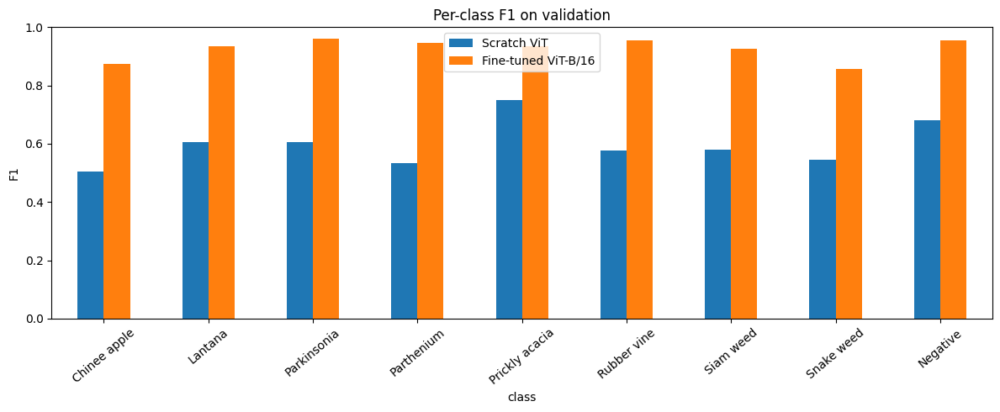

In [9]:
def per_class_metrics(frame):
    p, r, f, support = precision_recall_fscore_support(
        frame.y_true, frame.y_pred, labels=list(range(len(classes))), zero_division=0)
    counts = confusion_matrix(frame.y_true, frame.y_pred, labels=list(range(len(classes))))
    return pd.DataFrame({
        "class": classes, "precision": p, "recall": r, "f1": f,
        "support": support, "correct": np.diag(counts),
        "errors": support - np.diag(counts),
        "error_rate": np.divide(support - np.diag(counts), support,
                                out=np.zeros(len(classes), dtype=float), where=support > 0)
    })
per_class = {}
for name, frame in predictions.items():
    report = per_class_metrics(frame)
    per_class[name] = report
    display(pd.DataFrame({"model": [name]}).iloc[:0] if False else report.style.format(
        {"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "error_rate": "{:.1%}"}).set_caption(name))
    report.to_csv(OUT / (("scratch" if name.startswith("Scratch") else "finetuned") + "_per_class.csv"), index=False)
compare_f1 = pd.DataFrame({name: tab.set_index("class")["f1"] for name, tab in per_class.items()})
compare_f1.plot.bar(figsize=(12, 5), ylim=(0, 1), rot=40)
plt.title("Per-class F1 on validation"); plt.ylabel("F1"); plt.tight_layout()
plt.savefig(OUT / "per_class_f1.png", dpi=180); plt.show()
compare_f1.to_csv(OUT / "per_class_f1_comparison.csv")

## 6 · Error analysis: raw and row-normalised confusion matrices
Rows = true class, columns = predicted class. Row normalisation uses the number of true images of each class, not the number of predicted images.

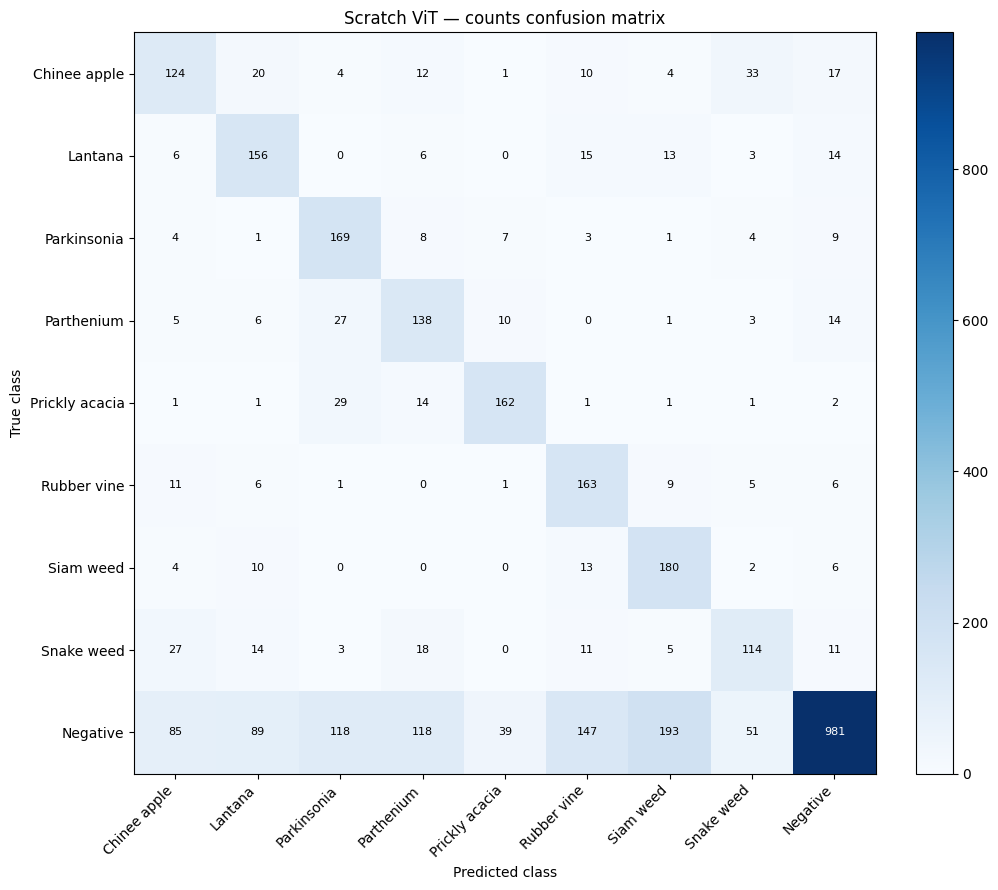

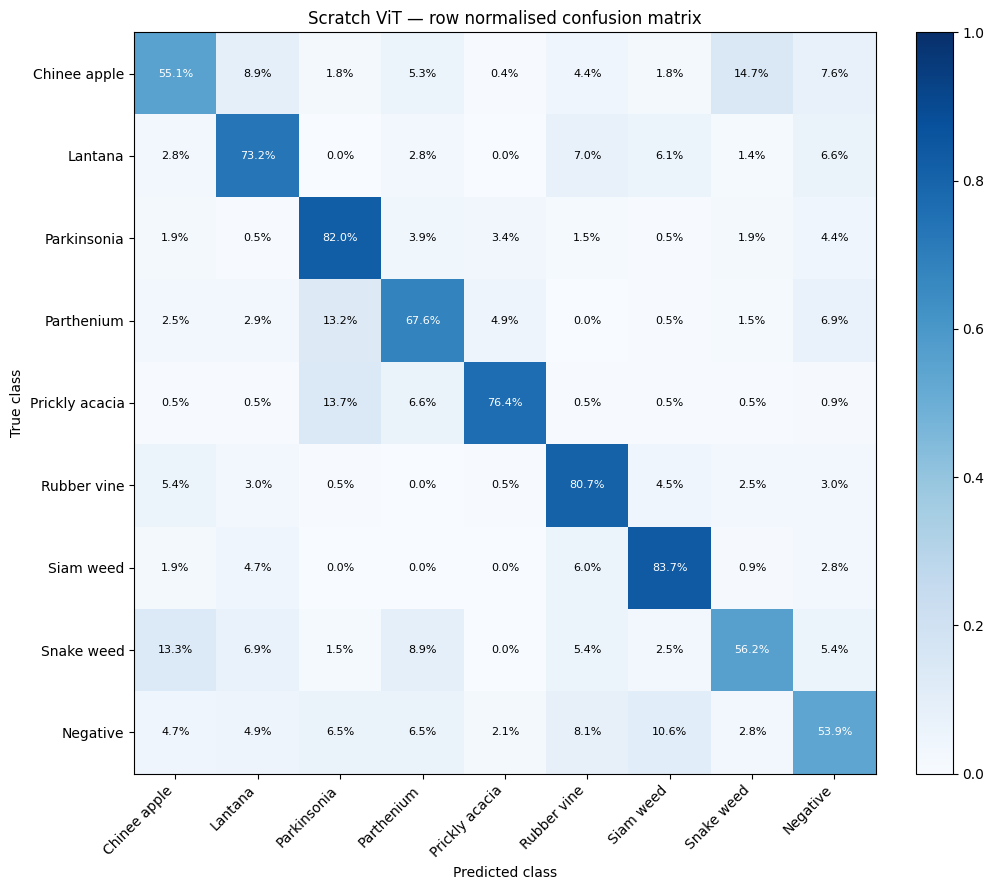

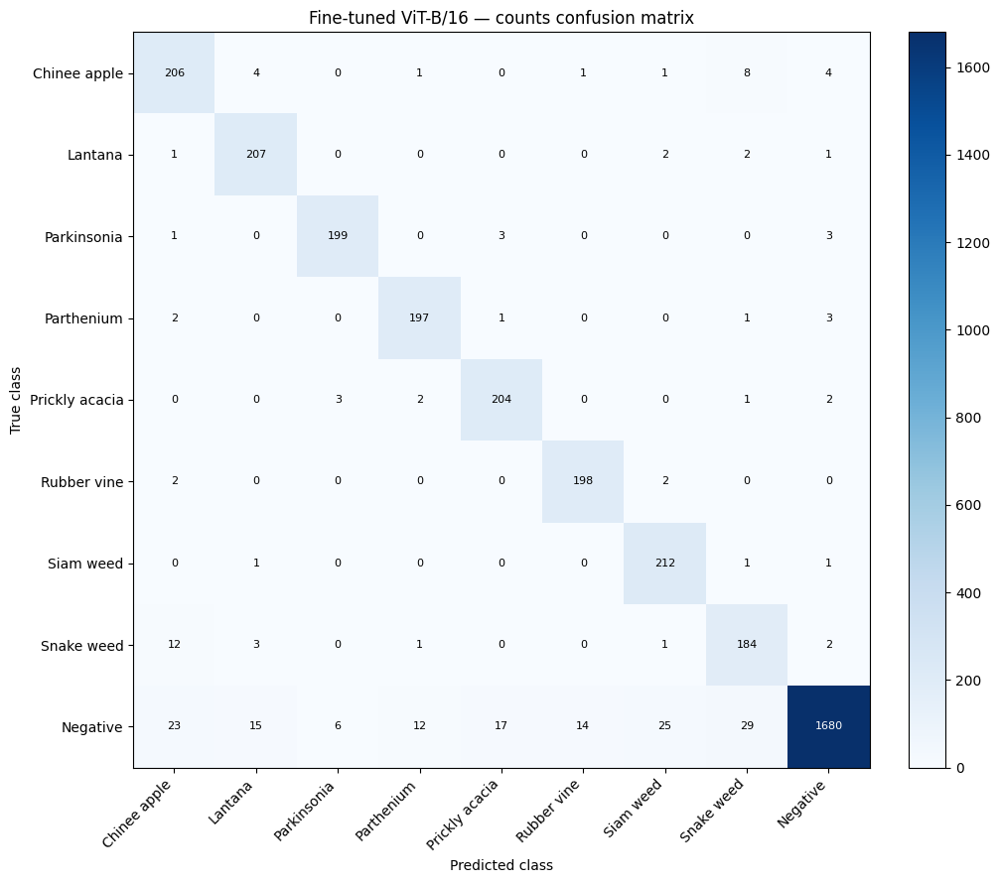

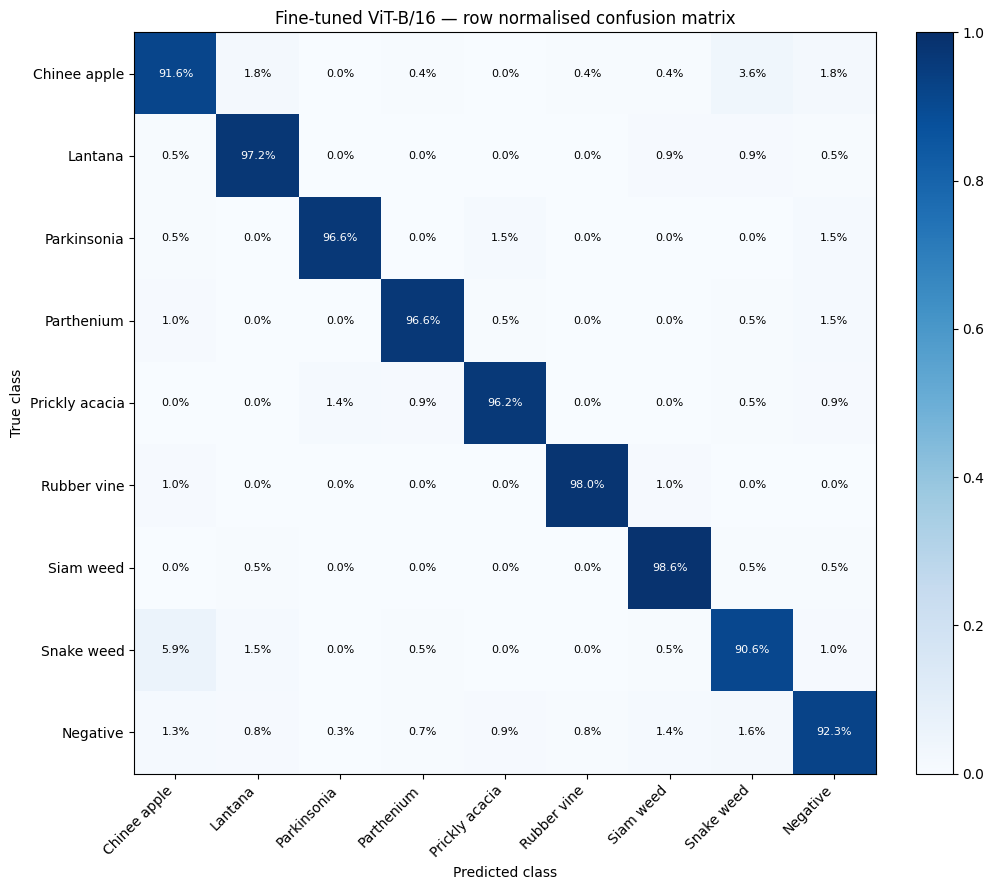

In [10]:
def plot_confusion(frame, name, slug):
    cm = confusion_matrix(frame.y_true, frame.y_pred, labels=list(range(len(classes))))
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
    for matrix, kind, fmt in [(cm, "counts", "d"), (cm_norm, "row_normalised", ".1%")]:
        fig, ax = plt.subplots(figsize=(11, 9))
        im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=(1 if kind == "row_normalised" else None))
        for i in range(len(classes)):
            for j in range(len(classes)):
                value = matrix[i, j]
                txt = f"{value:d}" if kind == "counts" else f"{value:.1%}"
                ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                        color="white" if value > (0.5 if kind == "row_normalised" else matrix.max() / 2) else "black")
        ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right")
        ax.set_yticks(range(len(classes)), classes)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
        ax.set_title(f"{name} — {kind.replace('_', ' ')} confusion matrix")
        fig.colorbar(im, ax=ax, fraction=.045, pad=.04)
        fig.tight_layout()
        fig.savefig(OUT / f"{slug}_confusion_{kind}.png", dpi=180)
        plt.show()
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(OUT / f"{slug}_confusion_counts.csv")
    pd.DataFrame(cm_norm, index=classes, columns=classes).to_csv(OUT / f"{slug}_confusion_row_normalised.csv")
    return cm, cm_norm

matrices = {}
for name, frame in predictions.items():
    slug = "scratch" if name.startswith("Scratch") else "finetuned"
    matrices[name] = plot_confusion(frame, name, slug)

## 7 · Dominant confusions for **each** class
For every true class, rank all incorrect predicted classes. Two denominators are included: `rate_of_true_class` (errors / all true images of this class) and `share_of_class_errors` (errors / incorrect images of this class). If a class has zero errors, the dominant prediction is reported as **None**.

In [11]:
dominant_rows = []
all_pairs = []
for name, (cm, _) in matrices.items():
    for i, true_name in enumerate(classes):
        errors = int(cm[i].sum() - cm[i, i])
        ranked = sorted([(j, int(cm[i, j])) for j in range(len(classes)) if j != i and cm[i, j] > 0],
                        key=lambda pair: (-pair[1], classes[pair[0]]))
        dominant_rows.append({
            "model": name, "true_class": true_name, "total_true": int(cm[i].sum()),
            "total_errors": errors,
            "dominant_confusion": classes[ranked[0][0]] if ranked else None,
            "dominant_count": ranked[0][1] if ranked else 0,
            "dominant_rate_of_true_class": ranked[0][1] / cm[i].sum() if ranked and cm[i].sum() else 0,
            "second_confusion": classes[ranked[1][0]] if len(ranked) > 1 else None,
            "third_confusion": classes[ranked[2][0]] if len(ranked) > 2 else None,
        })
        for rank, (j, count) in enumerate(ranked, 1):
            all_pairs.append({"model": name, "true_class": true_name,
                              "predicted_class": classes[j], "rank_within_true_class": rank,
                              "count": count, "rate_of_true_class": count / cm[i].sum(),
                              "share_of_class_errors": count / errors if errors else 0})
dominant = pd.DataFrame(dominant_rows)
pairs = pd.DataFrame(all_pairs)
display(dominant)
display(pairs.sort_values(["model", "count"], ascending=[True, False]).groupby("model").head(12))
dominant.to_csv(OUT / "dominant_confusion_by_class.csv", index=False)
pairs.to_csv(OUT / "all_confusion_pairs.csv", index=False)

,model,true_class,total_true,total_errors,dominant_confusion,dominant_count,dominant_rate_of_true_class,second_confusion,third_confusion
0,Scratch ViT,Chinee apple,225,101,Snake weed,33,0.146667,Lantana,Negative
1,Scratch ViT,Lantana,213,57,Rubber vine,15,0.070423,Negative,Siam weed
2,Scratch ViT,Parkinsonia,206,37,Negative,9,0.043689,Parthenium,Prickly acacia
3,Scratch ViT,Parthenium,204,66,Parkinsonia,27,0.132353,Negative,Prickly acacia
4,Scratch ViT,Prickly acacia,212,50,Parkinsonia,29,0.136792,Parthenium,Negative
5,Scratch ViT,Rubber vine,202,39,Chinee apple,11,0.054455,Siam weed,Lantana
6,Scratch ViT,Siam weed,215,35,Rubber vine,13,0.060465,Lantana,Negative
7,Scratch ViT,Snake weed,203,89,Chinee apple,27,0.133005,Parthenium,Lantana
8,Scratch ViT,Negative,1821,840,Siam weed,193,0.105986,Rubber vine,Parkinsonia
9,Fine-tuned ViT-B/16,Chinee apple,225,19,Snake weed,8,0.035556,Lantana,Negative


,model,true_class,predicted_class,rank_within_true_class,count,rate_of_true_class,share_of_class_errors
95,Fine-tuned ViT-B/16,Negative,Snake weed,1,29,0.015925,0.205674
96,Fine-tuned ViT-B/16,Negative,Siam weed,2,25,0.013729,0.177305
97,Fine-tuned ViT-B/16,Negative,Chinee apple,3,23,0.012630,0.163121
98,Fine-tuned ViT-B/16,Negative,Prickly acacia,4,17,0.009336,0.120567
99,Fine-tuned ViT-B/16,Negative,Lantana,5,15,0.008237,0.106383
100,Fine-tuned ViT-B/16,Negative,Rubber vine,6,14,0.007688,0.099291
90,Fine-tuned ViT-B/16,Snake weed,Chinee apple,1,12,0.059113,0.631579
101,Fine-tuned ViT-B/16,Negative,Parthenium,7,12,0.006590,0.085106
64,Fine-tuned ViT-B/16,Chinee apple,Snake weed,1,8,0.035556,0.421053
102,Fine-tuned ViT-B/16,Negative,Parkinsonia,8,6,0.003295,0.042553


## 8 · Actual misclassified images (12 per model)
Select **12 high-confidence errors** per model. This is an intentionally biased diagnostic gallery, **not** a representative random sample. The full prediction CSV contains all errors.



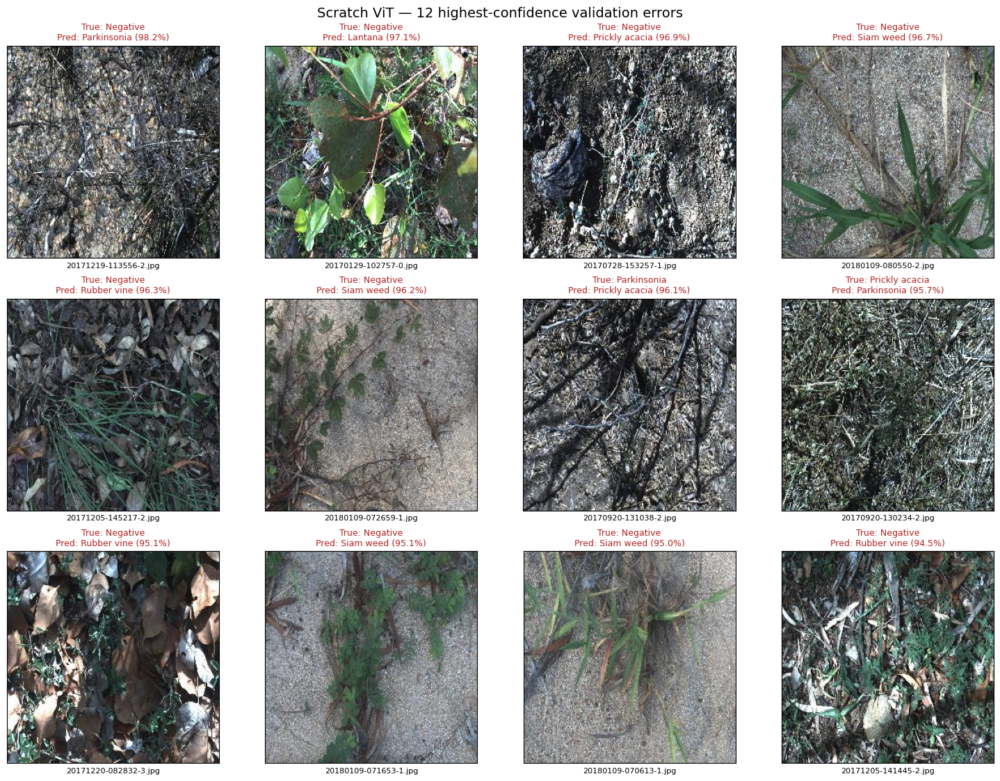

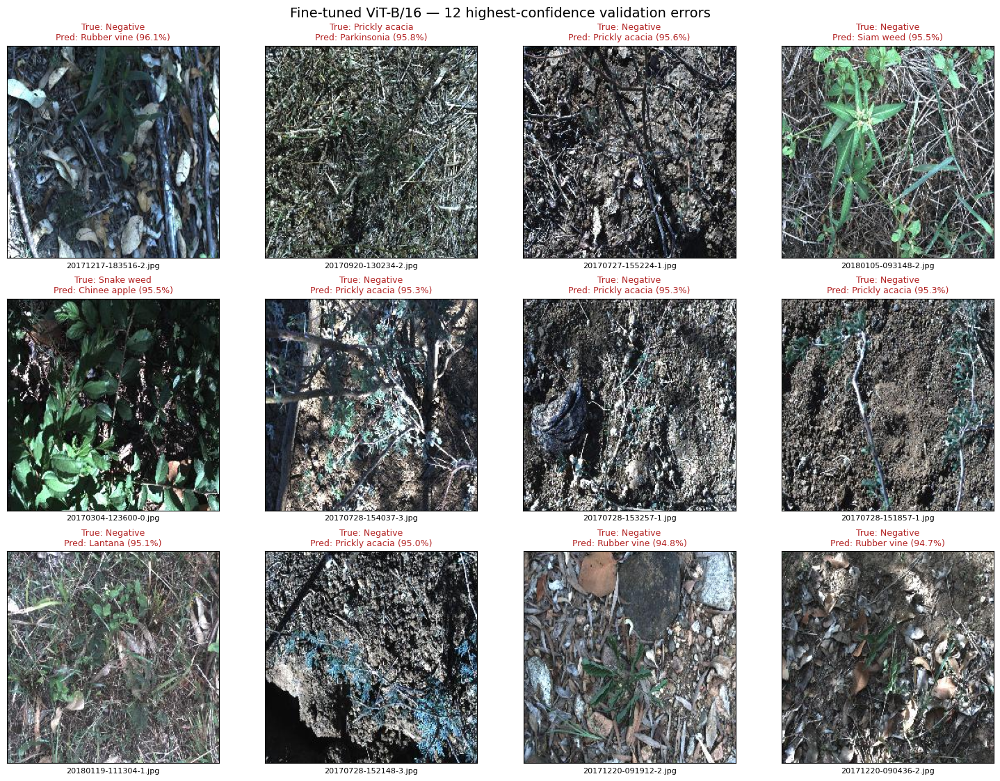

In [12]:
def image_path(filename):
    filename = str(filename).replace("\\", "/")
    direct = IMG_DIR / filename
    if direct.is_file():
        return direct
    fallback = IMG_DIR / Path(filename).name
    if fallback.is_file():
        return fallback
    raise FileNotFoundError(f"Cannot find image {filename!r} in {IMG_DIR}")

def gallery(frame, title, output_name, n=12, sort_by="confidence"):
    frame = frame.copy()
    if frame.empty:
        print(f"{title}: no images")
        return
    if sort_by in frame.columns:
        frame = frame.sort_values(sort_by, ascending=False)
    frame = frame.head(n)
    cols = 4
    nrows = int(np.ceil(len(frame) / cols))
    fig, axes = plt.subplots(nrows, cols, figsize=(15, nrows * 3.8))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, frame.iterrows()):
        with Image.open(image_path(row["Filename"])) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"True: {row['true_class']}\nPred: {row['predicted_class']} ({row['confidence']:.1%})",
                     fontsize=9, color=("firebrick" if not row["correct"] else "black"))
        ax.set_xlabel(Path(row["Filename"]).name, fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    for ax in axes[len(frame):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT / output_name, dpi=160, bbox_inches="tight")
    plt.show()

for name, frame in predictions.items():
    slug = "scratch" if name.startswith("Scratch") else "finetuned"
    gallery(frame.loc[~frame.correct], f"{name} — 12 highest-confidence validation errors",
            f"{slug}_misclassified_gallery.png", n=N_GALLERY)

## 9 · Galleries of dominant confusion pairs


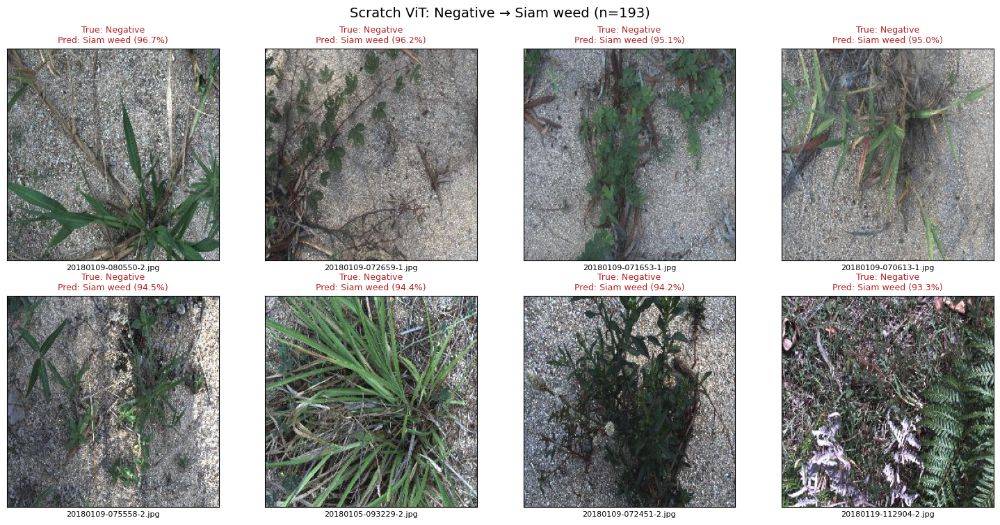

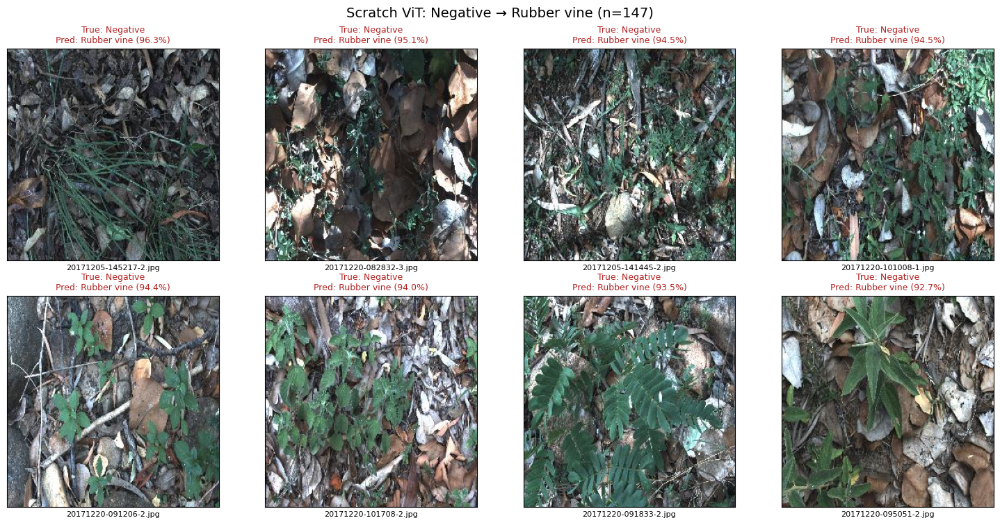

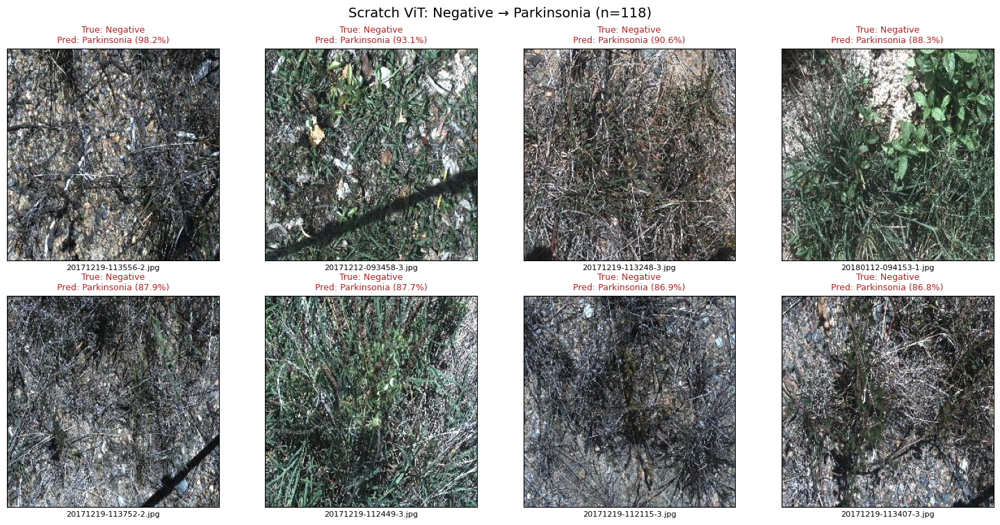

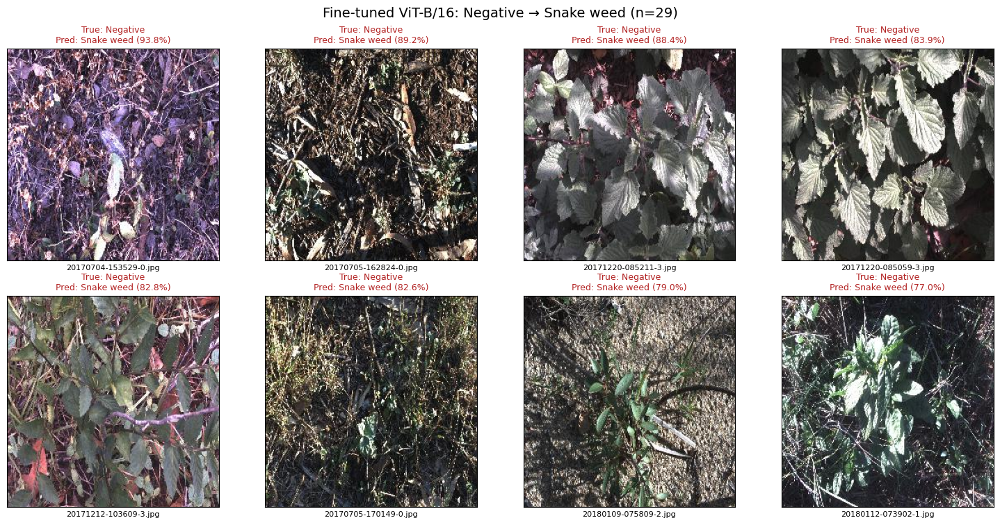

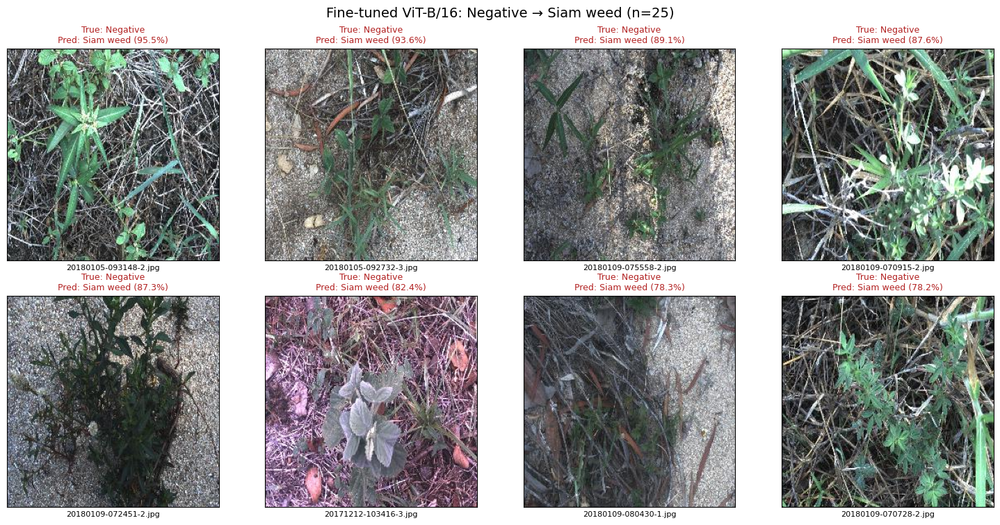

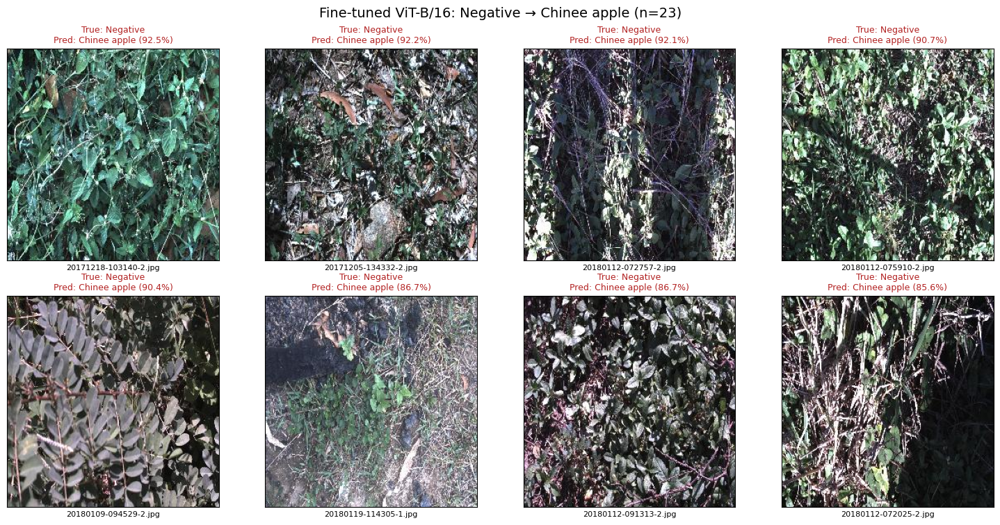

In [13]:
for name, frame in predictions.items():
    slug = "scratch" if name.startswith("Scratch") else "finetuned"
    top_pairs = pairs[pairs.model == name].nlargest(3, "count")
    for rank, row in enumerate(top_pairs.itertuples(index=False), 1):
        subset = frame[(frame.true_class == row.true_class) & (frame.predicted_class == row.predicted_class)]
        gallery(subset, f"{name}: {row.true_class} → {row.predicted_class} (n={len(subset)})",
                f"{slug}_confusion_pair_{rank}.png", n=8)

## 10 · Weed ↔ Negative: species-level false negatives


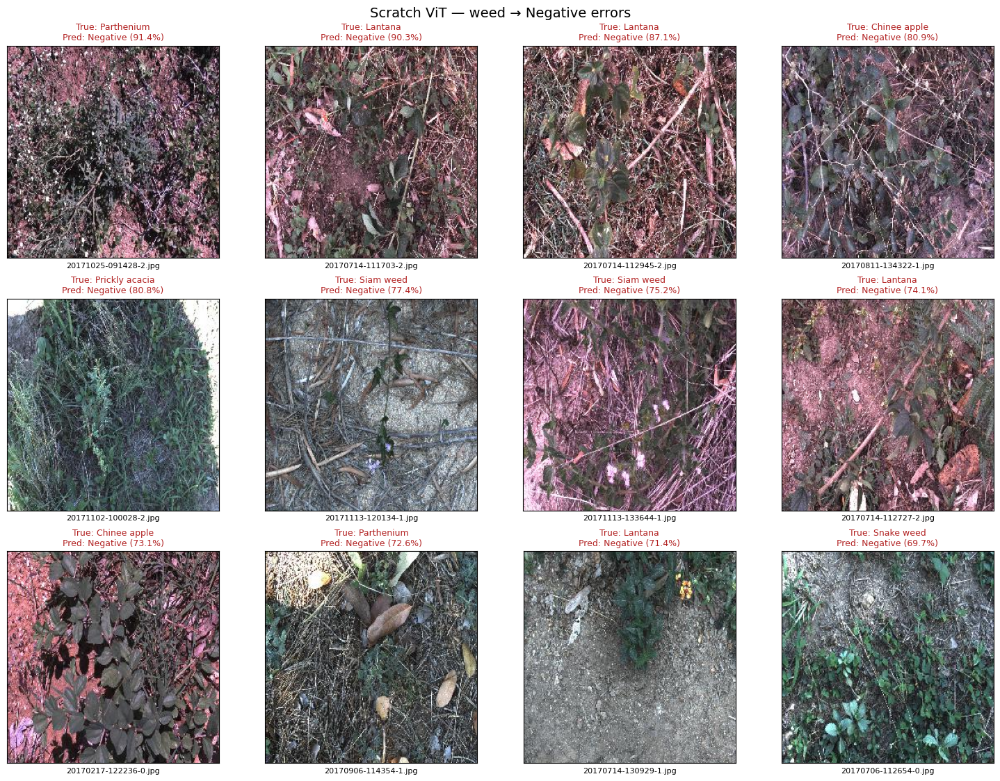

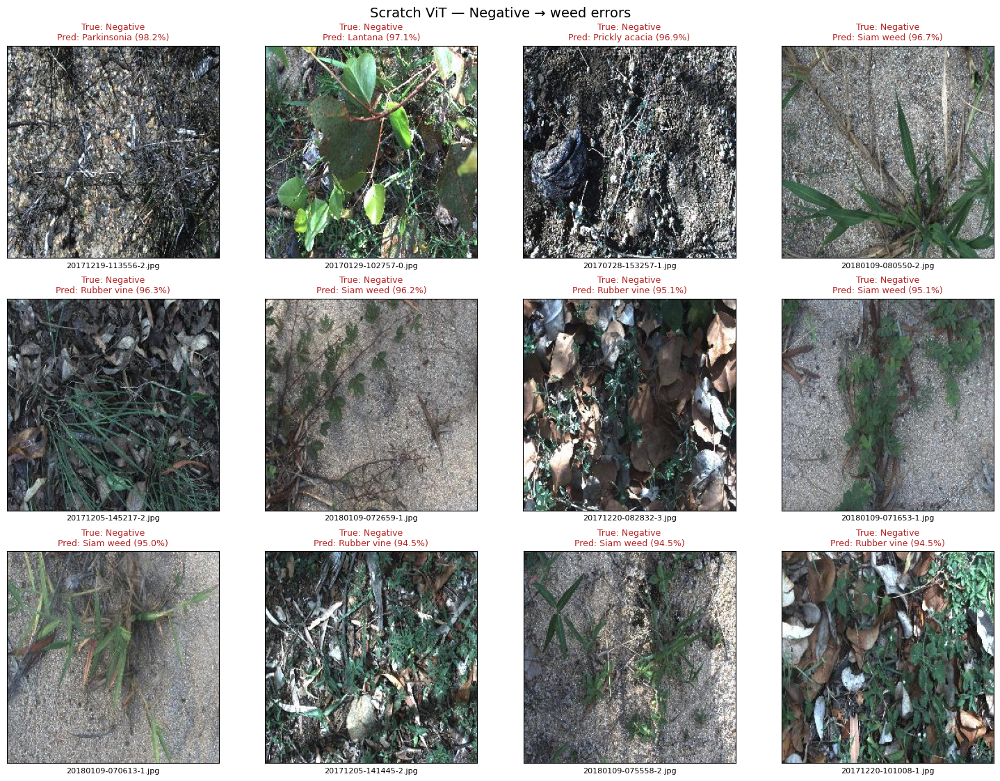

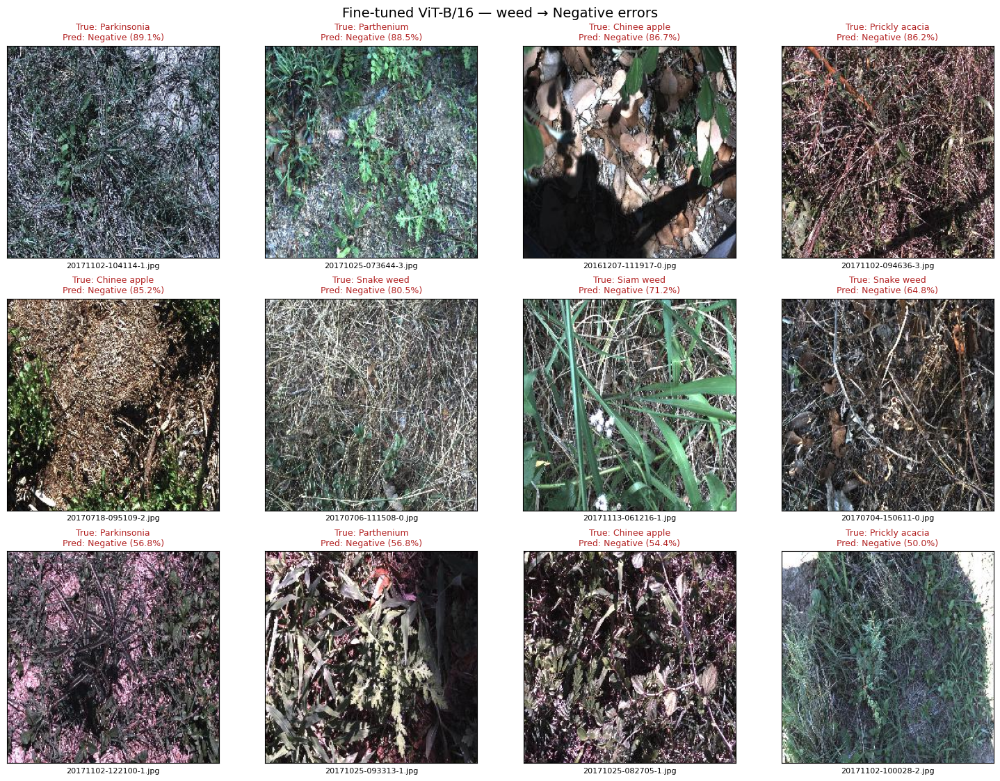

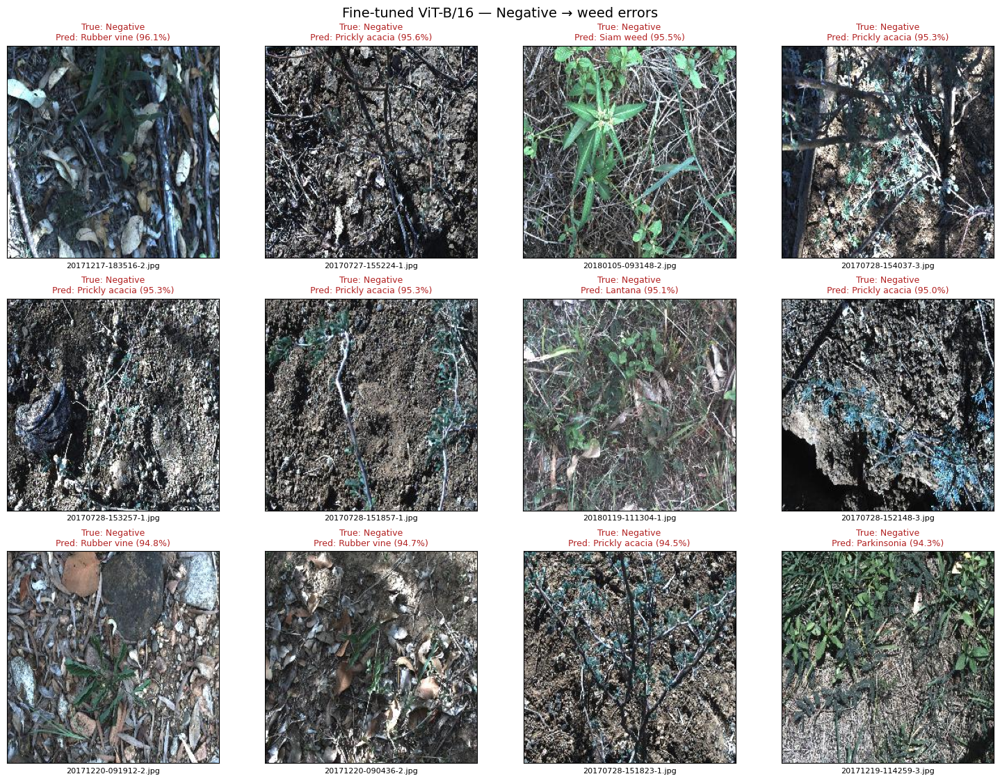

,model,weed_class,support,weed_to_negative_count,weed_to_negative_rate
0,Scratch ViT,Chinee apple,225,17,0.075556
1,Scratch ViT,Lantana,213,14,0.065728
2,Scratch ViT,Parkinsonia,206,9,0.043689
3,Scratch ViT,Parthenium,204,14,0.068627
4,Scratch ViT,Prickly acacia,212,2,0.009434
5,Scratch ViT,Rubber vine,202,6,0.029703
6,Scratch ViT,Siam weed,215,6,0.027907
7,Scratch ViT,Snake weed,203,11,0.054187
8,Fine-tuned ViT-B/16,Chinee apple,225,4,0.017778
9,Fine-tuned ViT-B/16,Lantana,213,1,0.004695


In [14]:
negative_tables = []
for name, frame in predictions.items():
    weed_rows = frame[frame.y_true != negative_idx]
    for species in (c for c in classes if c != classes[negative_idx]):
        subset = weed_rows[weed_rows.true_class == species]
        missed = subset[subset.y_pred == negative_idx]
        negative_tables.append({"model": name, "weed_class": species, "support": len(subset),
                                "weed_to_negative_count": len(missed),
                                "weed_to_negative_rate": len(missed) / len(subset) if len(subset) else np.nan})
    slug = "scratch" if name.startswith("Scratch") else "finetuned"
    gallery(frame[(frame.y_true != negative_idx) & (frame.y_pred == negative_idx)],
            f"{name} — weed → Negative errors", f"{slug}_weed_to_negative_gallery.png", n=12)
    gallery(frame[(frame.y_true == negative_idx) & (frame.y_pred != negative_idx)],
            f"{name} — Negative → weed errors", f"{slug}_negative_to_weed_gallery.png", n=12)
negative_table = pd.DataFrame(negative_tables)
display(negative_table)
negative_table.to_csv(OUT / "weed_to_negative_by_species.csv", index=False)

## 11 · Paired model disagreements


,images
category,
both_correct,2132
finetuned_only_correct,1155
both_wrong,159
scratch_only_correct,55


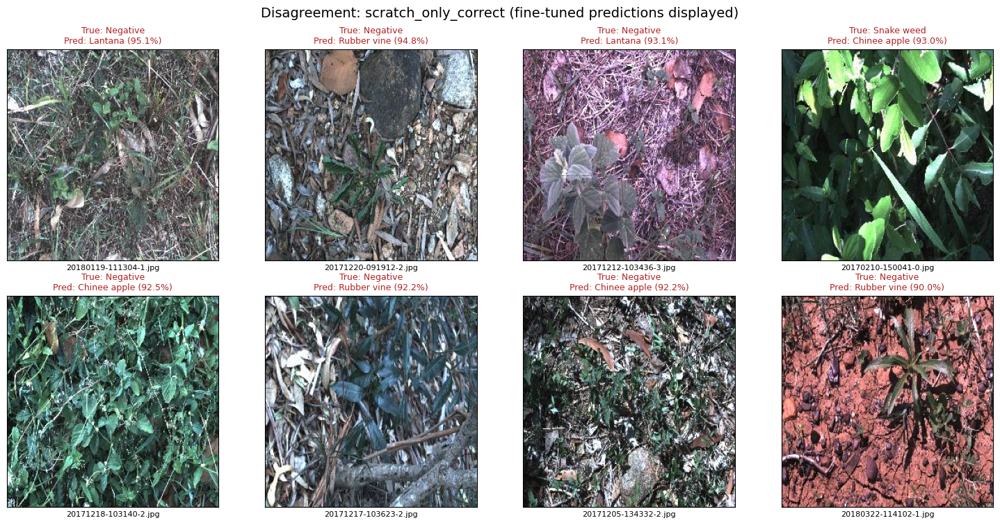

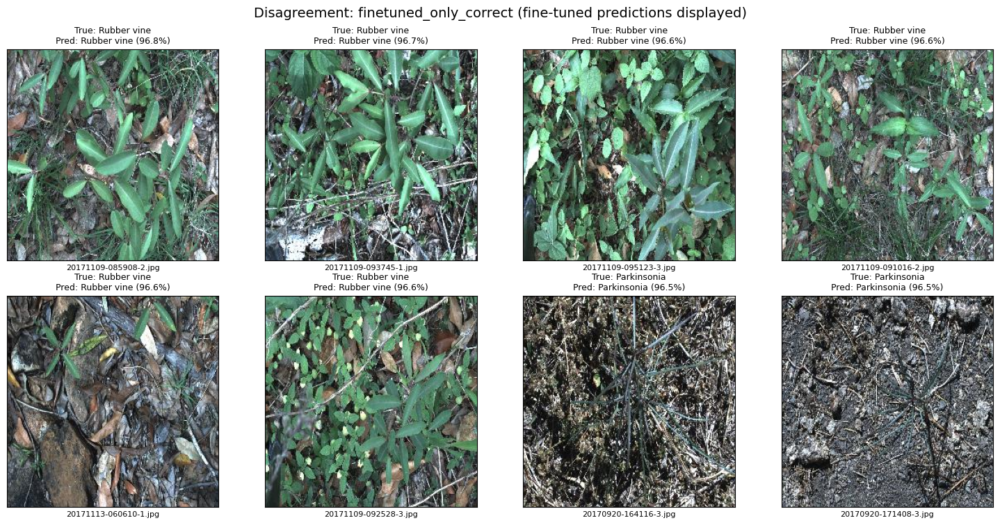

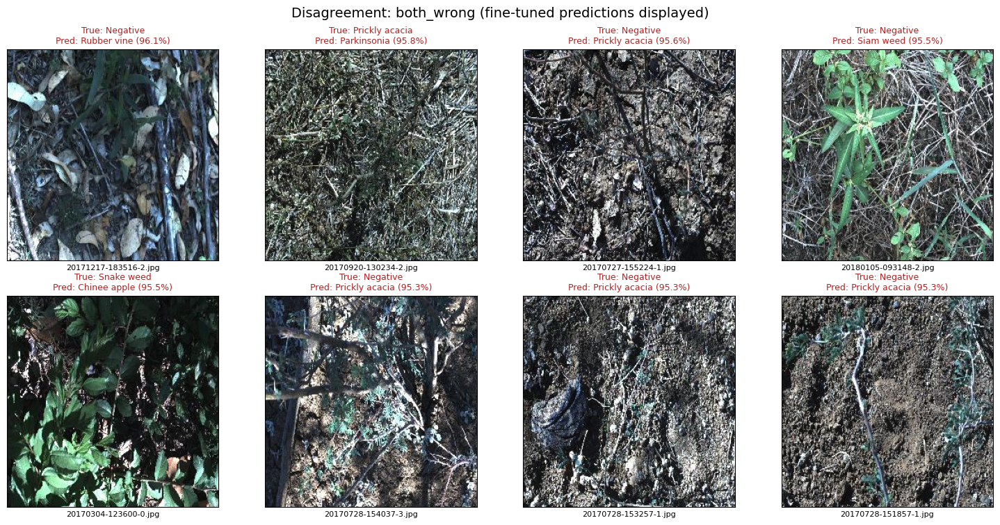

In [15]:
a = predictions["Scratch ViT"]
b = predictions["Fine-tuned ViT-B/16"]
joined = a[["Filename", "y_true", "true_class", "y_pred", "predicted_class", "confidence", "correct"]].merge(
    b[["Filename", "y_true", "y_pred", "predicted_class", "confidence", "correct"]],
    on="Filename", suffixes=("_scratch", "_finetuned"), validate="one_to_one")
assert (joined.y_true_scratch == joined.y_true_finetuned).all()
joined["category"] = np.select(
    [joined.correct_scratch & joined.correct_finetuned,
     joined.correct_scratch & ~joined.correct_finetuned,
     ~joined.correct_scratch & joined.correct_finetuned],
    ["both_correct", "scratch_only_correct", "finetuned_only_correct"],
    default="both_wrong")
display(joined.category.value_counts().rename_axis("category").to_frame("images"))
joined.to_csv(OUT / "model_disagreements.csv", index=False)
for category in ("scratch_only_correct", "finetuned_only_correct", "both_wrong"):
    subset = joined[joined.category == category].copy()
    subset["true_class"] = subset["true_class"]
    subset["predicted_class"] = subset["predicted_class_finetuned"]
    subset["confidence"] = subset["confidence_finetuned"]
    subset["correct"] = subset["correct_finetuned"]
    gallery(subset, f"Disagreement: {category} (fine-tuned predictions displayed)",
            f"disagreement_{category}.png", n=8)

## 12 · Confidence and high-confidence failures


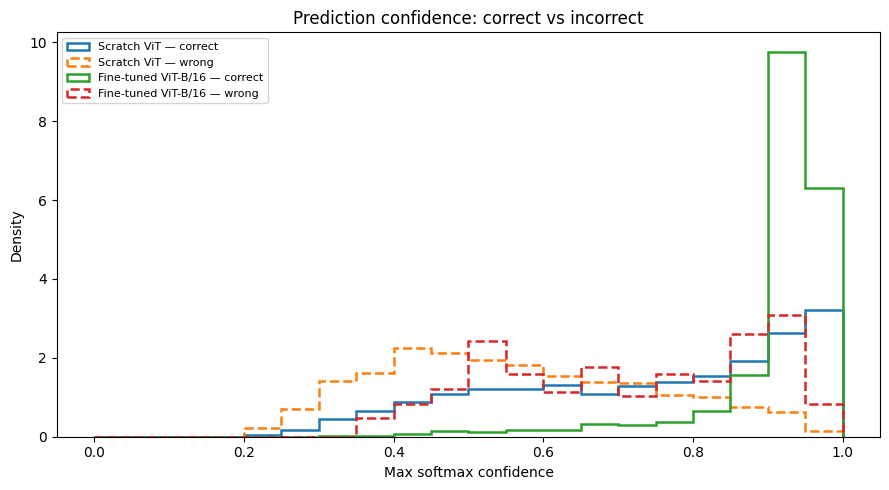

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, frame in predictions.items():
    for correct, style in [(True, "-"), (False, "--")]:
        vals = frame.loc[frame.correct == correct, "confidence"]
        if len(vals):
            ax.hist(vals, bins=np.linspace(0, 1, 21), density=True, histtype="step",
                    linewidth=1.8, linestyle=style, label=f"{name} — {'correct' if correct else 'wrong'}")
ax.set_xlabel("Max softmax confidence"); ax.set_ylabel("Density")
ax.set_title("Prediction confidence: correct vs incorrect")
ax.legend(fontsize=8); plt.tight_layout()
plt.savefig(OUT / "confidence_distributions.png", dpi=180); plt.show()

## 13 · Failure-mode annotation workflow


In [17]:
FAILURE_TAGS = ["lighting_shadow", "leaf_morphology_similarity", "background_clutter",
                "occlusion", "small_or_distant_plant", "multiple_plants",
                "negative_class_confusion", "other_uncertain"]
review_rows = []
rng = np.random.default_rng(SEED)
for name, frame in predictions.items():
    wrong = frame[~frame.correct]
    correct = frame[frame.correct]
    # Up to 10 correct controls per class per model; deterministic sampling.
    controls = (pd.concat([g.sample(n=min(len(g), 10), random_state=SEED)
                               for _, g in correct.groupby("true_class")], ignore_index=True))
    for _, row in pd.concat([wrong, controls]).iterrows():
        review_rows.append({"model": name, "Filename": row.Filename, "true_class": row.true_class,
                            "predicted_class": row.predicted_class, "correct": bool(row.correct),
                            "confidence": float(row.confidence), "reviewed": "",
                            "reviewer_notes": "", **{tag: "" for tag in FAILURE_TAGS}})
review_template = pd.DataFrame(review_rows)
template_path = OUT / "failure_mode_review_template.csv"
if not template_path.exists():
    review_template.to_csv(template_path, index=False)
    print("Created annotation template:", template_path)
else:
    print("Existing annotation template preserved (not overwritten):", template_path)
print("Rows available for review:", len(review_template))

Created annotation template: C:\Coding\CS3244\Github\CS3244-DeepWeeds\outputs\vit\paper_fold_validation_analysis\failure_mode_review_template.csv
Rows available for review: 1708


In [18]:
# After annotating the CSV, rerun this cell to summarise only reviewed images.
reviewed = pd.read_csv(template_path)
reviewed_flag = reviewed["reviewed"].astype(str).str.lower().isin(["1", "true", "yes", "y"])
reviewed = reviewed.loc[reviewed_flag].copy()
if reviewed.empty:
    print("No reviewed rows yet. Open failure_mode_review_template.csv and mark reviewed=1.")
else:
    for tag in FAILURE_TAGS:
        reviewed[tag] = pd.to_numeric(reviewed[tag], errors="coerce")
    if reviewed[FAILURE_TAGS].isna().any().any():
        warnings.warn("Some reviewed rows have missing tag values; complete all tag columns with 0 or 1.")
    summary = reviewed.groupby(["model", "correct"])[FAILURE_TAGS].agg(["sum", "mean"])
    display(summary)
    summary.to_csv(OUT / "annotated_failure_mode_summary.csv")
    pair_summary = reviewed.loc[~reviewed.correct].groupby(
        ["model", "true_class", "predicted_class"])[FAILURE_TAGS].mean()
    pair_summary.to_csv(OUT / "annotated_failure_modes_by_confusion_pair.csv")
    display(pair_summary.head(25))
    print("Interpret as descriptive associations; annotations are not a controlled lighting/morphology experiment.")

No reviewed rows yet. Open failure_mode_review_template.csv and mark reviewed=1.


## 14 · Paired bootstrap uncertainty (exploratory)


In [19]:
y = joined["y_true_scratch"].to_numpy()
pa = joined["y_pred_scratch"].to_numpy()
pb = joined["y_pred_finetuned"].to_numpy()
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(BOOTSTRAP_REPS):
    idx = rng.integers(0, len(y), len(y))
    diffs.append({
        "macro_f1_diff_finetuned_minus_scratch":
            f1_score(y[idx], pb[idx], labels=list(range(len(classes))), average="macro", zero_division=0)
            - f1_score(y[idx], pa[idx], labels=list(range(len(classes))), average="macro", zero_division=0),
        "accuracy_diff_finetuned_minus_scratch":
            accuracy_score(y[idx], pb[idx]) - accuracy_score(y[idx], pa[idx])
    })
boot = pd.DataFrame(diffs)
ci = boot.quantile([0.025, 0.5, 0.975]).T
ci.columns = ["ci_2.5%", "bootstrap_median", "ci_97.5%"]
display(ci)
ci.to_csv(OUT / "paired_bootstrap_intervals.csv")

,ci_2.5%,bootstrap_median,ci_97.5%
macro_f1_diff_finetuned_minus_scratch,0.311694,0.329597,0.346611
accuracy_diff_finetuned_minus_scratch,0.298486,0.314482,0.329906


In [20]:
summary = {
    "split": SPLIT, "val_fold": VAL_FOLD, "n_validation": len(val_manifest), "n_test": len(test_manifest),
    "class_order": classes,
    "checkpoints": {name: (SCRATCH_PATH.name if name.startswith("Scratch") else HF_PATH.name) for name in models},
    "validation_metrics": {name: {k: (int(v) if isinstance(v, (int, np.integer)) else float(v))
                       for k, v in overall_metrics(frame).items()} for name, frame in predictions.items()},
    "test_metrics": {name: {k: (int(v) if isinstance(v, (int, np.integer)) else float(v))
                           for k, v in overall_metrics(frame).items()} for name, frame in test_predictions.items()},
    "top_directed_confusions": {
        name: pairs[pairs.model == name].nlargest(5, "count")[
            ["true_class", "predicted_class", "count", "rate_of_true_class"]
        ].to_dict(orient="records") for name in models
    },
    "limitations": [
        "Reference paper not supplied; no verified paper-pair reproduction claim.",
        "Failure-mode tags require manual review and are descriptive, not causal.",
        "Image-level bootstrap does not account for within-session correlation.",
        "Detailed error analysis and bootstrap use validation only; test is aggregate metrics only."
    ]
}
(OUT / "paper_fold_validation_test_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Saved paper fold validation analysis and test metrics under:", OUT)
print("No weights updated and no training performed.")

Saved paper fold validation analysis and test metrics under: C:\Coding\CS3244\Github\CS3244-DeepWeeds\outputs\vit\paper_fold_validation_analysis
No weights updated and no training performed.


c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
c:\Users\bairo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:259: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
